# GEO và nhãn mua theo không gian

Notebook chứa mã phân tích theo đúng thứ tự từ các file nguồn trong `src/`. Chạy với kernel của `.venv` tại repo. Các bước có thể đọc toàn bộ raw và ghi vào `outputs/`; kiểm tra phạm vi và quy ước thời gian của từng phần trước khi diễn giải. Mã cũ dùng UTC hoặc mẫu là phương pháp cũ, chưa được coi là kết quả Moscow/toàn bộ khách hàng. Script nguồn vẫn được giữ để đối chiếu.

In [1]:
from pathlib import Path
import sys
import time
import pandas as pd
from IPython.display import display, Image, SVG, Markdown
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'pyproject.toml').exists())
sys.path.insert(0, str(ROOT / 'src'))
sys.path.insert(0, str(ROOT / 'src/scripts'))
sys.path.insert(0, str(ROOT / 'src/mbd_mini_eda_fixes'))
def show_generated_results(started_ns, source):
    changed = sorted((p for base in (ROOT / 'outputs', ROOT / 'docs') if base.exists() for p in base.rglob('*') if p.is_file() and p.stat().st_mtime_ns >= started_ns), key=lambda p: p.as_posix())
    display(Markdown(f'### Kết quả: `{source}`'))
    if not changed:
        display(Markdown('Không có file kết quả mới từ phần này.'))
        return
    images = [p for p in changed if p.suffix.lower() in ('.png', '.jpg', '.jpeg', '.svg')]
    png_stems = {p.with_suffix('') for p in images if p.suffix.lower() == '.png'}
    for p in images:
        if p.suffix.lower() == '.svg' and p.with_suffix('') in png_stems:
            continue
        display(Markdown(f'**{p.relative_to(ROOT).as_posix()}**'))
        display(SVG(filename=str(p)) if p.suffix.lower() == '.svg' else Image(filename=str(p)))
    tables = [p for p in changed if p.suffix.lower() == '.csv']
    for p in tables:
        display(Markdown(f'**{p.relative_to(ROOT).as_posix()}** — 5 dòng đầu'))
        try:
            display(pd.read_csv(p, nrows=5))
        except Exception as exc:
            display(Markdown(f'Không đọc được bảng: `{type(exc).__name__}: {exc}`'))
    others = [p.relative_to(ROOT).as_posix() for p in changed if p not in images and p not in tables]
    if others:
        display(Markdown('File kết quả khác: ' + ', '.join(f'`{p}`' for p in others)))

## Analyze Geo Spatial Purchase Moscow

Nguồn: `src/scripts/analyze_geo_spatial_purchase_moscow.py`. Chạy các ô của phần này theo thứ tự.

In [2]:
__file__ = str(ROOT / 'src/scripts/analyze_geo_spatial_purchase_moscow.py')
sys.argv = [__file__]
__eda_started_ns = time.time_ns()
__name__ = '__main__'
__package__ = None


In [3]:
"""Independent-customer spatial association audit at the last complete H=3 cutoff.

Raw timezone-naive event timestamps retain the project's existing UTC interpretation;
calendar and cutoff use Moscow. No raw mutation or predictive target encoding.
"""
from pathlib import Path
import json
import numpy as np
import pandas as pd
import duckdb
from scipy.stats import norm
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

OUT=Path('outputs/geo_spatial_purchase_moscow_20261117')
OUT.mkdir(parents=True,exist_ok=True)
CUTOFF='2022-10-31 21:00:00'
SEED=20261117
PERMUTATIONS=999


def wilson(k,n):
    k=np.asarray(k,dtype=float);n=np.asarray(n,dtype=float)
    z=norm.ppf(.975);p=k/n;den=1+z*z/n
    center=(p+z*z/(2*n))/den
    half=z*np.sqrt(p*(1-p)/n+z*z/(4*n*n))/den
    return np.clip(center-half,0,1),np.clip(center+half,0,1)


def rates(frame,groups,h):
    r=frame.groupby(groups,dropna=False,observed=True)[f'y_{h}'].agg(['size','sum','mean']).reset_index()
    r=r.rename(columns={'size':'n','sum':'buyers','mean':'rate'})
    r['wilson_low'],r['wilson_high']=wilson(r.buyers,r.n)
    r['horizon']=h
    return r


def build_snapshot():
    cache=OUT/'customer_snapshot.parquet'
    if cache.exists():
        print('Loading Moscow snapshot cache',flush=True)
        return pd.read_parquet(cache)
    c=duckdb.connect()
    c.execute('SET threads=2')
    c.execute("SET memory_limit='3GB'")
    c.execute('SET preserve_insertion_order=false')
    c.execute(f"SET temp_directory='{OUT.as_posix()}/duckdb_tmp'")
    parts=[]
    for fold in range(5):
        # Each customer's raw history occurs in one fold; final uniqueness is checked.
        c.execute(f"CREATE OR REPLACE TEMP TABLE cells AS SELECT client_id,geohash_4 g4,geohash_5 g5,geohash_6 g6,count(*) events FROM read_parquet('data/MBD-mini/detail/geo/fold={fold}/*.parquet') WHERE event_time<TIMESTAMP '{CUTOFF}' GROUP BY 1,2,3,4")
        assert c.execute('SELECT count(*) FROM cells WHERE g4 IS NULL OR g5 IS NULL OR g6 IS NULL').fetchone()[0]==0
        for level,parent in [(4,''),(5,'g4,'),(6,'g4,g5,')]:
            c.execute(f'CREATE OR REPLACE TEMP TABLE f{level} AS SELECT client_id,{parent}g{level},sum(events) events FROM cells GROUP BY ALL')
        # Nested modal path: most frequent g4, then g5 within it, then g6 within g5.
        c.execute('CREATE OR REPLACE TEMP TABLE m4 AS SELECT * FROM f4 QUALIFY row_number() OVER(PARTITION BY client_id ORDER BY events DESC,g4)=1')
        c.execute('CREATE OR REPLACE TEMP TABLE m5 AS SELECT f5.* FROM f5 JOIN m4 USING(client_id,g4) QUALIFY row_number() OVER(PARTITION BY client_id ORDER BY f5.events DESC,g5)=1')
        c.execute('CREATE OR REPLACE TEMP TABLE m6 AS SELECT f6.* FROM f6 JOIN m5 USING(client_id,g4,g5) QUALIFY row_number() OVER(PARTITION BY client_id ORDER BY f6.events DESC,g6)=1')
        g=c.execute('''SELECT a.*,m4.g4,m5.g5,m6.g6,m4.events::DOUBLE/a.geo_events geo_top_g4_share,
            m6.events::DOUBLE/a.geo_events geo_nested_g6_share
            FROM (SELECT client_id,sum(events) geo_events,count(distinct g4) geo_cells_g4,
            count(distinct g5) geo_cells_g5,count(distinct g6) geo_cells_g6 FROM cells GROUP BY client_id) a
            JOIN m4 USING(client_id) JOIN m5 USING(client_id) JOIN m6 USING(client_id)''').df()
        t=c.execute(f"SELECT client_id,count(*) trx_events,count(distinct cast(event_time+INTERVAL '3 hours' AS DATE)) trx_active_days FROM read_parquet('data/MBD-mini/detail/trx/fold={fold}/*.parquet') WHERE event_time<TIMESTAMP '{CUTOFF}' GROUP BY client_id").df()
        ids=c.execute(f"SELECT DISTINCT client_id FROM read_parquet('data/MBD-mini/client_split/fold={fold}/*.parquet')").df()
        parts.append(ids.merge(g,on='client_id',how='left',validate='one_to_one').merge(t,on='client_id',how='left',validate='one_to_one'))
        print(f'Full-history snapshot fold {fold} complete',flush=True)
    d=pd.concat(parts,ignore_index=True)
    assert d.client_id.is_unique and len(d)==100224
    counts=['geo_events','geo_cells_g4','geo_cells_g5','geo_cells_g6','trx_events','trx_active_days']
    d[counts]=d[counts].fillna(0).astype('int64')
    d['has_geo']=d.geo_events.gt(0)
    c.execute("CREATE TEMP TABLE targets AS SELECT client_id,cast(mon AS DATE) mon,target_1,target_2,target_3,target_4 FROM read_parquet('data/MBD-mini/targets/**/*.parquet') WHERE cast(mon AS DATE)>=DATE '2022-11-01'")
    assert c.execute('SELECT count(*) FROM targets WHERE target_1 IS NULL OR target_2 IS NULL OR target_3 IS NULL OR target_4 IS NULL').fetchone()[0]==0
    labels=c.execute('''SELECT client_id,count(*) AS months,
        max(greatest(target_1,target_2,target_3,target_4)) FILTER(WHERE mon<DATE '2022-12-01')::INT y_1,
        max(greatest(target_1,target_2,target_3,target_4)) FILTER(WHERE mon<DATE '2023-01-01')::INT y_2,
        max(greatest(target_1,target_2,target_3,target_4))::INT y_3 FROM targets GROUP BY client_id''').df()
    assert labels.months.eq(3).all()
    d=d.merge(labels.drop(columns='months'),on='client_id',validate='one_to_one')
    # Feature-only quintiles, with ties kept together; no fit on outcomes.
    d['trx_stratum']='T0: no TRX'
    positive=d.trx_events.gt(0)
    bins,bounds=pd.qcut(d.loc[positive,'trx_events'],5,labels=False,retbins=True)
    d.loc[positive,'trx_stratum']=['T'+str(int(v)+1) for v in bins]
    pd.DataFrame({'stratum':['T'+str(i) for i in range(1,6)],'lower_edge':bounds[:-1],'upper_edge':bounds[1:]}).to_csv(OUT/'trx_stratum_edges.csv',index=False)
    d['cutoff_moscow']='2022-11-01T00:00:00+03:00'
    d['cutoff_utc']='2022-10-31T21:00:00Z'
    d.to_parquet(cache,index=False)
    return d

In [4]:
def hierarchical_tables(d):
    geo=d[d.has_geo].copy()
    for child,parent in [('g5','g4'),('g6','g5')]:
        assert geo.groupby(child)[parent].nunique().max()==1
    result=[];support=[]
    for h in [1,2,3]:
        global_rate=d[f'y_{h}'].mean()
        raw={}
        for level,parent in [('g4',None),('g5','g4'),('g6','g5')]:
            keys=[level] if parent is None else [parent,level]
            raw[level]=rates(geo,keys,h)
            r=raw[level]
            support.append(dict(horizon=h,level=level,cells=len(r),cells_n_ge100=int(r.n.ge(100).sum()),
                customers_n_ge100=int(r.loc[r.n.ge(100),'n'].sum()),median_n=r.n.median(),cells_n_lt10=int(r.n.lt(10).sum()),geo_customers=len(geo)))
        for strength in [20,100,500]:
            previous=None
            for level,parent in [('g4',None),('g5','g4'),('g6','g5')]:
                r=raw[level].copy()
                if parent is None:
                    r['prior_mean']=global_rate
                else:
                    r['prior_mean']=r[parent].map(previous.set_index(parent).smoothed)
                r['smoothed']=(r.buyers+strength*r.prior_mean)/(r.n+strength)
                r['data_weight']=r.n/(r.n+strength)
                r['strength']=strength;r['level']=level
                r['cell']=r[level]
                r['parent_cell']=np.nan if parent is None else r[parent]
                r['baseline_all']=global_rate
                r['meets_display_n100']=r.n.ge(100)
                previous=r
                result.append(r[['horizon','level','cell','parent_cell','n','buyers','rate','wilson_low','wilson_high','prior_mean','smoothed','data_weight','strength','baseline_all','meets_display_n100']])
    t=pd.concat(result,ignore_index=True)
    t.to_csv(OUT/'hierarchical_cell_rates.csv',index=False)
    pd.DataFrame(support).to_csv(OUT/'cell_support.csv',index=False)
    return t


def stratified_rates(d):
    presence=[];features=[];standard=[]
    weights=d.trx_stratum.value_counts(normalize=True).sort_index()
    for h in [1,2,3]:
        a=rates(d,['trx_stratum','has_geo'],h)
        baselines=d.groupby('trx_stratum')[f'y_{h}'].mean()
        a['stratum_baseline']=a.trx_stratum.map(baselines)
        a['lift_vs_stratum']=a.rate/a.stratum_baseline
        comparison=a.pivot(index='trx_stratum',columns='has_geo',values='rate')
        a['rr_geo_vs_no_geo']=a.trx_stratum.map(comparison[True]/comparison[False].replace(0,np.nan))
        presence.append(a)
        both=comparison.dropna()
        w=weights.reindex(both.index);w=w/w.sum()
        std_geo=(both[True]*w).sum();std_no=(both[False]*w).sum()
        crude=d.groupby('has_geo')[f'y_{h}'].mean()
        av=a.set_index(['trx_stratum','has_geo'])
        variances=[]
        for has in [True,False]:
            counts=av.xs(has,level='has_geo').reindex(both.index)
            variances.append(float(np.sum(w*w*counts.rate*(1-counts.rate)/counts.n)))
        log_se=np.sqrt(variances[0]/std_geo**2+variances[1]/std_no**2)
        standard.append(dict(horizon=h,crude_geo=crude[True],crude_no_geo=crude[False],crude_rr=crude[True]/crude[False],
            standardized_geo=std_geo,standardized_no_geo=std_no,standardized_rr=std_geo/std_no,
            standardized_rr_low=np.exp(np.log(std_geo/std_no)-norm.ppf(.975)*log_se),
            standardized_rr_high=np.exp(np.log(std_geo/std_no)+norm.ppf(.975)*log_se),
            standardized_risk_difference=std_geo-std_no,common_strata=len(both),retained_target_population_weight=weights.reindex(both.index).sum()))
    for feature in ['geo_events','geo_cells_g4','geo_top_g4_share']:
        # Bands defined independently within each TRX stratum, only GEO-positive customers.
        d['feature_band']='No GEO'
        for stratum,g in d[d.has_geo].groupby('trx_stratum'):
            bins,bounds=pd.qcut(g[feature],4,labels=False,retbins=True,duplicates='drop')
            if len(bounds)==1:
                d.loc[g.index,'feature_band']='Q1 (all equal)'
            else:
                d.loc[g.index,'feature_band']=['Q'+str(int(v)+1) for v in bins]
            pd.DataFrame({'feature':[feature]*(len(bounds)-1),'trx_stratum':[stratum]*(len(bounds)-1),'band':['Q'+str(i+1) for i in range(len(bounds)-1)],'lower_edge':bounds[:-1],'upper_edge':bounds[1:]}).to_csv(OUT/f'edges_{feature}_{stratum.split(":")[0]}.csv',index=False)
        for h in [1,2,3]:
            b=rates(d,['trx_stratum','feature_band'],h)
            b['feature']=feature
            b['baseline_stratum_all']=b.trx_stratum.map(d.groupby('trx_stratum')[f'y_{h}'].mean())
            b['baseline_stratum_geo']=b.trx_stratum.map(d[d.has_geo].groupby('trx_stratum')[f'y_{h}'].mean())
            b['lift_vs_stratum_all']=b.rate/b.baseline_stratum_all.replace(0,np.nan)
            b['lift_vs_stratum_geo']=b.rate/b.baseline_stratum_geo.replace(0,np.nan)
            features.append(b)
    p=pd.concat(presence,ignore_index=True);f=pd.concat(features,ignore_index=True);s=pd.DataFrame(standard)
    p.to_csv(OUT/'has_geo_by_trx_stratum.csv',index=False)
    f.to_csv(OUT/'feature_lift_by_trx_stratum.csv',index=False)
    s.to_csv(OUT/'geo_direct_standardization.csv',index=False)
    return p,f,s

In [5]:
def permutation_tests(d):
    """Sparse-safe global statistic, permutations preserving TRX-stratum totals."""
    geo=d[d.has_geo].reset_index(drop=True)
    strata=[np.asarray(v) for v in geo.groupby('trx_stratum').indices.values()]
    encoded={level:pd.factorize(geo[level],sort=True)[0] for level in ['g4','g5']}
    output=[]
    for h in [1,2,3]:
        y=geo[f'y_{h}'].to_numpy(dtype=float)
        for condition in ['unconditional','within_trx_strata']:
            p=np.full(len(y),y.mean())
            blocks=[np.arange(len(y))] if condition=='unconditional' else strata
            if condition=='within_trx_strata':
                for ix in blocks:p[ix]=y[ix].mean()
            specs={}
            for level,code in encoded.items():
                n=np.bincount(code)
                expected=np.bincount(code,weights=p)
                variance=np.bincount(code,weights=p*(1-p))
                keep=variance>0
                def statistic(values,code=code,expected=expected,variance=variance,keep=keep):
                    obs=np.bincount(code,weights=values,minlength=len(expected))
                    return float(np.sum((obs[keep]-expected[keep])**2/variance[keep]))
                specs[level]=(statistic,statistic(y),[])
            rng=np.random.default_rng(SEED+h+(100 if condition=='within_trx_strata' else 0))
            for _ in range(PERMUTATIONS):
                yp=y.copy()
                for ix in blocks:yp[ix]=rng.permutation(y[ix])
                for statistic,observed,null in specs.values():null.append(statistic(yp))
            for level,(statistic,observed,null) in specs.items():
                null=np.asarray(null)
                output.append(dict(horizon=h,level=level,condition=condition,customers=len(y),cells=len(np.unique(encoded[level])),
                    statistic=observed,null_mean=null.mean(),null_p95=np.quantile(null,.95),
                    permutation_p=(1+int((null>=observed).sum()))/(PERMUTATIONS+1),permutations=PERMUTATIONS))
        print(f'Permutation H={h} complete',flush=True)
    t=pd.DataFrame(output)
    # Holm adjustment across all 12 planned global tests.
    order=np.argsort(t.permutation_p.to_numpy())
    adjusted=np.maximum.accumulate(t.permutation_p.to_numpy()[order]*(len(t)-np.arange(len(t))))
    t['holm_p']=0.0;t.loc[order,'holm_p']=np.minimum(adjusted,1)
    t.to_csv(OUT/'global_cell_permutation.csv',index=False)
    return t


def plots(cells,presence,features):
    plt.rcParams.update({'font.size':10})
    # Display largest cells by support, not by apparent purchase rate.
    fig,axes=plt.subplots(1,2,figsize=(14,6),dpi=170)
    for ax,level in zip(axes,['g4','g5']):
        z=cells[(cells.horizon==3)&(cells.strength==100)&(cells.level==level)&cells.n.ge(100)].nlargest(15,'n').sort_values('n')
        if z.empty:
            ax.text(.5,.5,'No cells with n >= 100',ha='center',transform=ax.transAxes);continue
        yy=np.arange(len(z))
        ax.errorbar(z.rate,yy,xerr=np.vstack([np.maximum(0,z.rate-z.wilson_low),np.maximum(0,z.wilson_high-z.rate)]),fmt='o',color='#8293a8',label='Raw rate + 95% Wilson')
        ax.scatter(z.smoothed,yy,marker='D',s=24,color='#208575',label='Hierarchical shrinkage, m=100',zorder=3)
        ax.axvline(z.baseline_all.iloc[0],ls='--',color='grey',lw=1)
        ax.set_yticks(yy,[f'{int(row.cell)} (n={int(row.n)})' for row in z.itertuples()])
        ax.xaxis.set_major_formatter(PercentFormatter(1));ax.set_title(f'{level}: 15 largest assigned cells, n >= 100')
        ax.set_xlabel('3-month cumulative purchase rate');ax.grid(axis='x',alpha=.2);ax.legend(fontsize=8)
    fig.suptitle('Cell purchase rates | cutoff 01 Nov 2022 Moscow | one assignment per customer',fontsize=14)
    fig.tight_layout(rect=(0,0,1,.94));fig.savefig(OUT/'cell_rates_wilson.png');plt.close(fig)
    fig,axes=plt.subplots(1,3,figsize=(15,5.5),dpi=170,sharey=True)
    strata=sorted(presence.trx_stratum.unique())
    for ax,h in zip(axes,[1,2,3]):
        for has,color in [(False,'#8293a8'),(True,'#208575')]:
            z=presence[(presence.horizon==h)&(presence.has_geo==has)].set_index('trx_stratum').reindex(strata)
            xx=np.arange(len(strata))+(int(has)-.5)*.32
            ax.bar(xx,z.rate,width=.3,color=color,label='Has GEO' if has else 'No GEO')
            ax.errorbar(xx,z.rate,yerr=np.vstack([np.maximum(0,z.rate-z.wilson_low),np.maximum(0,z.wilson_high-z.rate)]),fmt='none',ecolor='#193454',lw=.8,capsize=2)
        ax.set_xticks(range(len(strata)),[s.split(':')[0] for s in strata]);ax.set_title(f'Horizon {h} month(s)')
        ax.yaxis.set_major_formatter(PercentFormatter(1));ax.grid(axis='y',alpha=.2);ax.set_axisbelow(True);ax.set_xlabel('Full-history TRX event-count stratum')
    axes[0].set_ylabel('Purchase rate (95% Wilson)');axes[0].legend()
    fig.suptitle('GEO coverage association within TRX activity strata | Moscow cutoff',fontsize=15)
    fig.tight_layout(rect=(0,.02,1,.92));fig.savefig(OUT/'has_geo_stratified.png');plt.close(fig)
    fig,axes=plt.subplots(1,3,figsize=(15,6),dpi=170)
    for ax,feature in zip(axes,['geo_events','geo_cells_g4','geo_top_g4_share']):
        z=features[(features.horizon==3)&(features.feature==feature)&features.feature_band.ne('No GEO')]
        mat=z.pivot(index='trx_stratum',columns='feature_band',values='lift_vs_stratum_geo').sort_index()
        im=ax.imshow(mat,aspect='auto',cmap='RdBu_r',vmin=.5,vmax=1.5)
        for i in range(len(mat)):
            for j in range(len(mat.columns)):
                v=mat.iloc[i,j]
                if pd.notna(v):ax.text(j,i,f'{v:.2f}',ha='center',va='center',fontsize=9)
        ax.set_xticks(range(len(mat.columns)),mat.columns,rotation=25);ax.set_yticks(range(len(mat)),mat.index)
        ax.set_title({'geo_events':'GEO event count','geo_cells_g4':'Distinct g4 cells','geo_top_g4_share':'Main g4 event share'}[feature]);ax.set_xlabel('Within-stratum GEO-positive quartile')
    fig.suptitle('H=3 feature-group lift within TRX strata | full pre-cutoff history',fontsize=15)
    fig.subplots_adjust(left=.08,right=.85,bottom=.2,top=.84,wspace=.4)
    color_axis=fig.add_axes([.89,.25,.015,.5])
    fig.colorbar(im,cax=color_axis,label='Lift vs GEO-positive customers in same TRX stratum')
    fig.savefig(OUT/'feature_lift_stratified.png');plt.close(fig)

In [6]:
def main():
    d=build_snapshot()
    assert d.client_id.is_unique and len(d)==100224
    assert (d.y_1<=d.y_2).all() and (d.y_2<=d.y_3).all()
    assert d.geo_top_g4_share.dropna().between(0,1).all()
    cells=hierarchical_tables(d)
    p,f,s=stratified_rates(d)
    tests=permutation_tests(d)
    plots(cells,p,f)
    manifest={'timezone':'Europe/Moscow (UTC+3)','cutoff_moscow':'2022-11-01T00:00:00+03:00','cutoff_utc':CUTOFF+'Z',
        'raw_naive_timestamp_assumption':'UTC, retained from existing project convention; source ETL timezone unverified',
        'history':'All available event_time < cutoff, independently per source','customers':len(d),'geo_customers':int(d.has_geo.sum()),
        'horizons':[1,2,3],'cell_assignment':'Nested modal g4 -> modal g5 within chosen g4 -> modal g6 within chosen g5; count events, tie by smallest code',
        'cell_denominator':'Unique customers assigned to the cell; not all visitors','ci':'95% pointwise Wilson, not simultaneous intervals',
        'shrinkage':'(buyers + m * parent_smoothed_rate) / (n + m); g4 prior = all-customer baseline; m=20,100,500 sensitivity',
        'shrinkage_warning':'Descriptive in-sample plug-in smoothing, not fitted empirical Bayes, not target encoding for prediction; no posterior CI claimed',
        'trx_strata':'No TRX + feature-only quintiles of positive full-history TRX event counts; equal counts kept together',
        'feature_bands':'Within each TRX stratum, GEO-positive quartiles; ties kept, duplicate boundaries dropped',
        'permutations':PERMUTATIONS,'seed':SEED,'permutation_caveat':'Exchangeability assumed within coarse TRX strata; residual confounding remains',
        'validation':'No horizon choice, no predictive model or top-K recommendation; single-cutoff descriptive association'}
    (OUT/'manifest.json').write_text(json.dumps(manifest,ensure_ascii=False,indent=2),encoding='utf-8')
    print('STANDARDIZATION\n'+s.to_string(index=False))
    print('SUPPORT\n'+pd.read_csv(OUT/'cell_support.csv').query('horizon==3').to_string(index=False))
    print('GLOBAL TESTS\n'+tests.to_string(index=False))
    print('STRATA H3\n'+p[p.horizon==3].to_string(index=False))


if __name__=='__main__':main()

Loading Moscow snapshot cache


Permutation H=1 complete


Permutation H=2 complete


Permutation H=3 complete


STANDARDIZATION
 horizon  crude_geo  crude_no_geo  crude_rr  standardized_geo  standardized_no_geo  standardized_rr  standardized_rr_low  standardized_rr_high  standardized_risk_difference  common_strata  retained_target_population_weight
       1   0.009409      0.006779  1.388044          0.009233             0.007152         1.290985             1.099319              1.516067                      0.002081              6                                1.0
       2   0.017375      0.012105  1.435291          0.017109             0.012726         1.344368             1.193269              1.514599                      0.004383              6                                1.0
       3   0.023839      0.016359  1.457218          0.023372             0.017501         1.335462             1.205989              1.478836                      0.005871              6                                1.0
SUPPORT
 horizon level  cells  cells_n_ge100  customers_n_ge100  median_n  cells_n_lt10  geo

### Kết quả: `src/scripts/analyze_geo_spatial_purchase_moscow.py`

**outputs/geo_spatial_purchase_moscow_20261117/cell_rates_wilson.png**

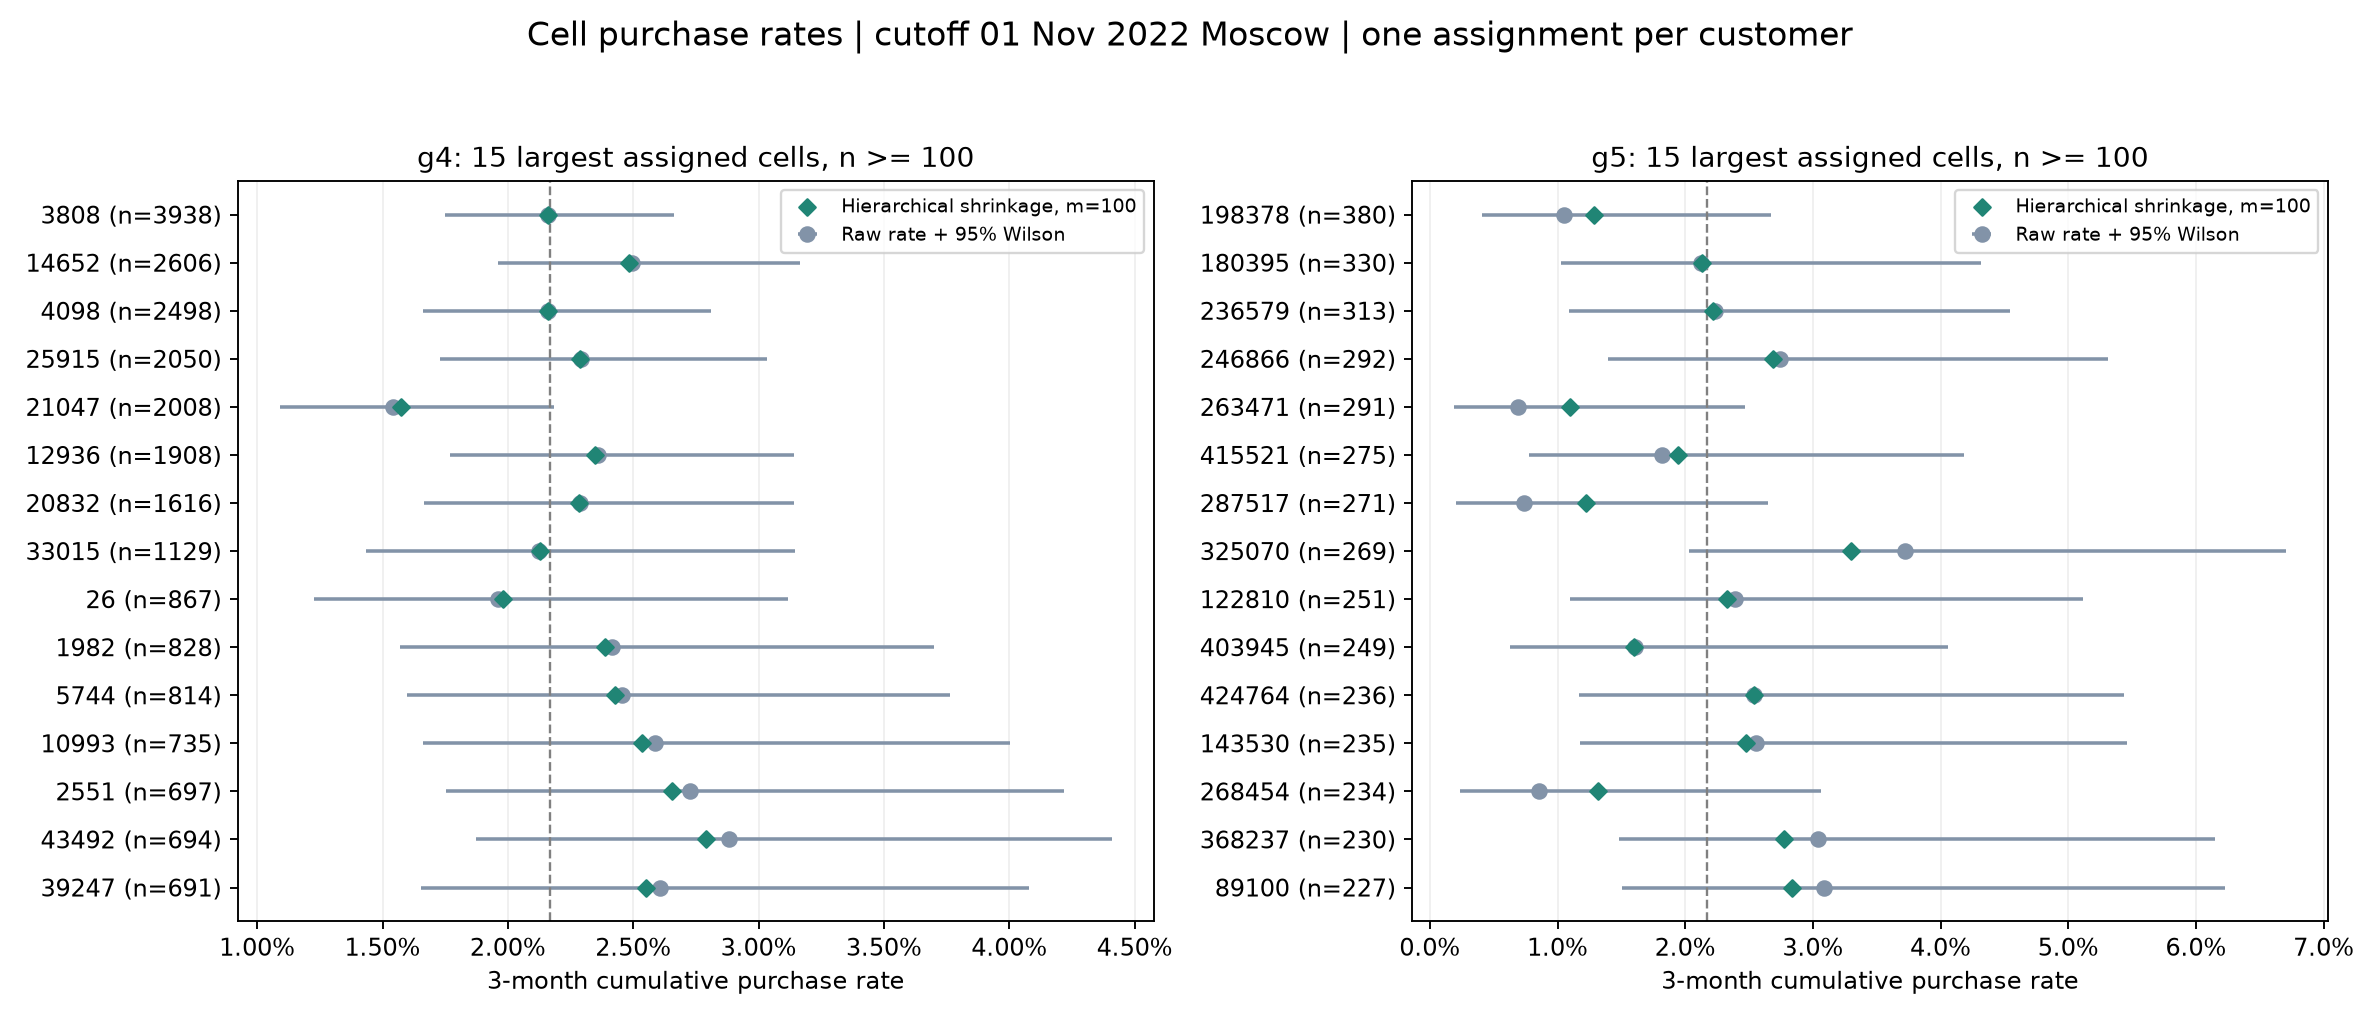

**outputs/geo_spatial_purchase_moscow_20261117/feature_lift_stratified.png**

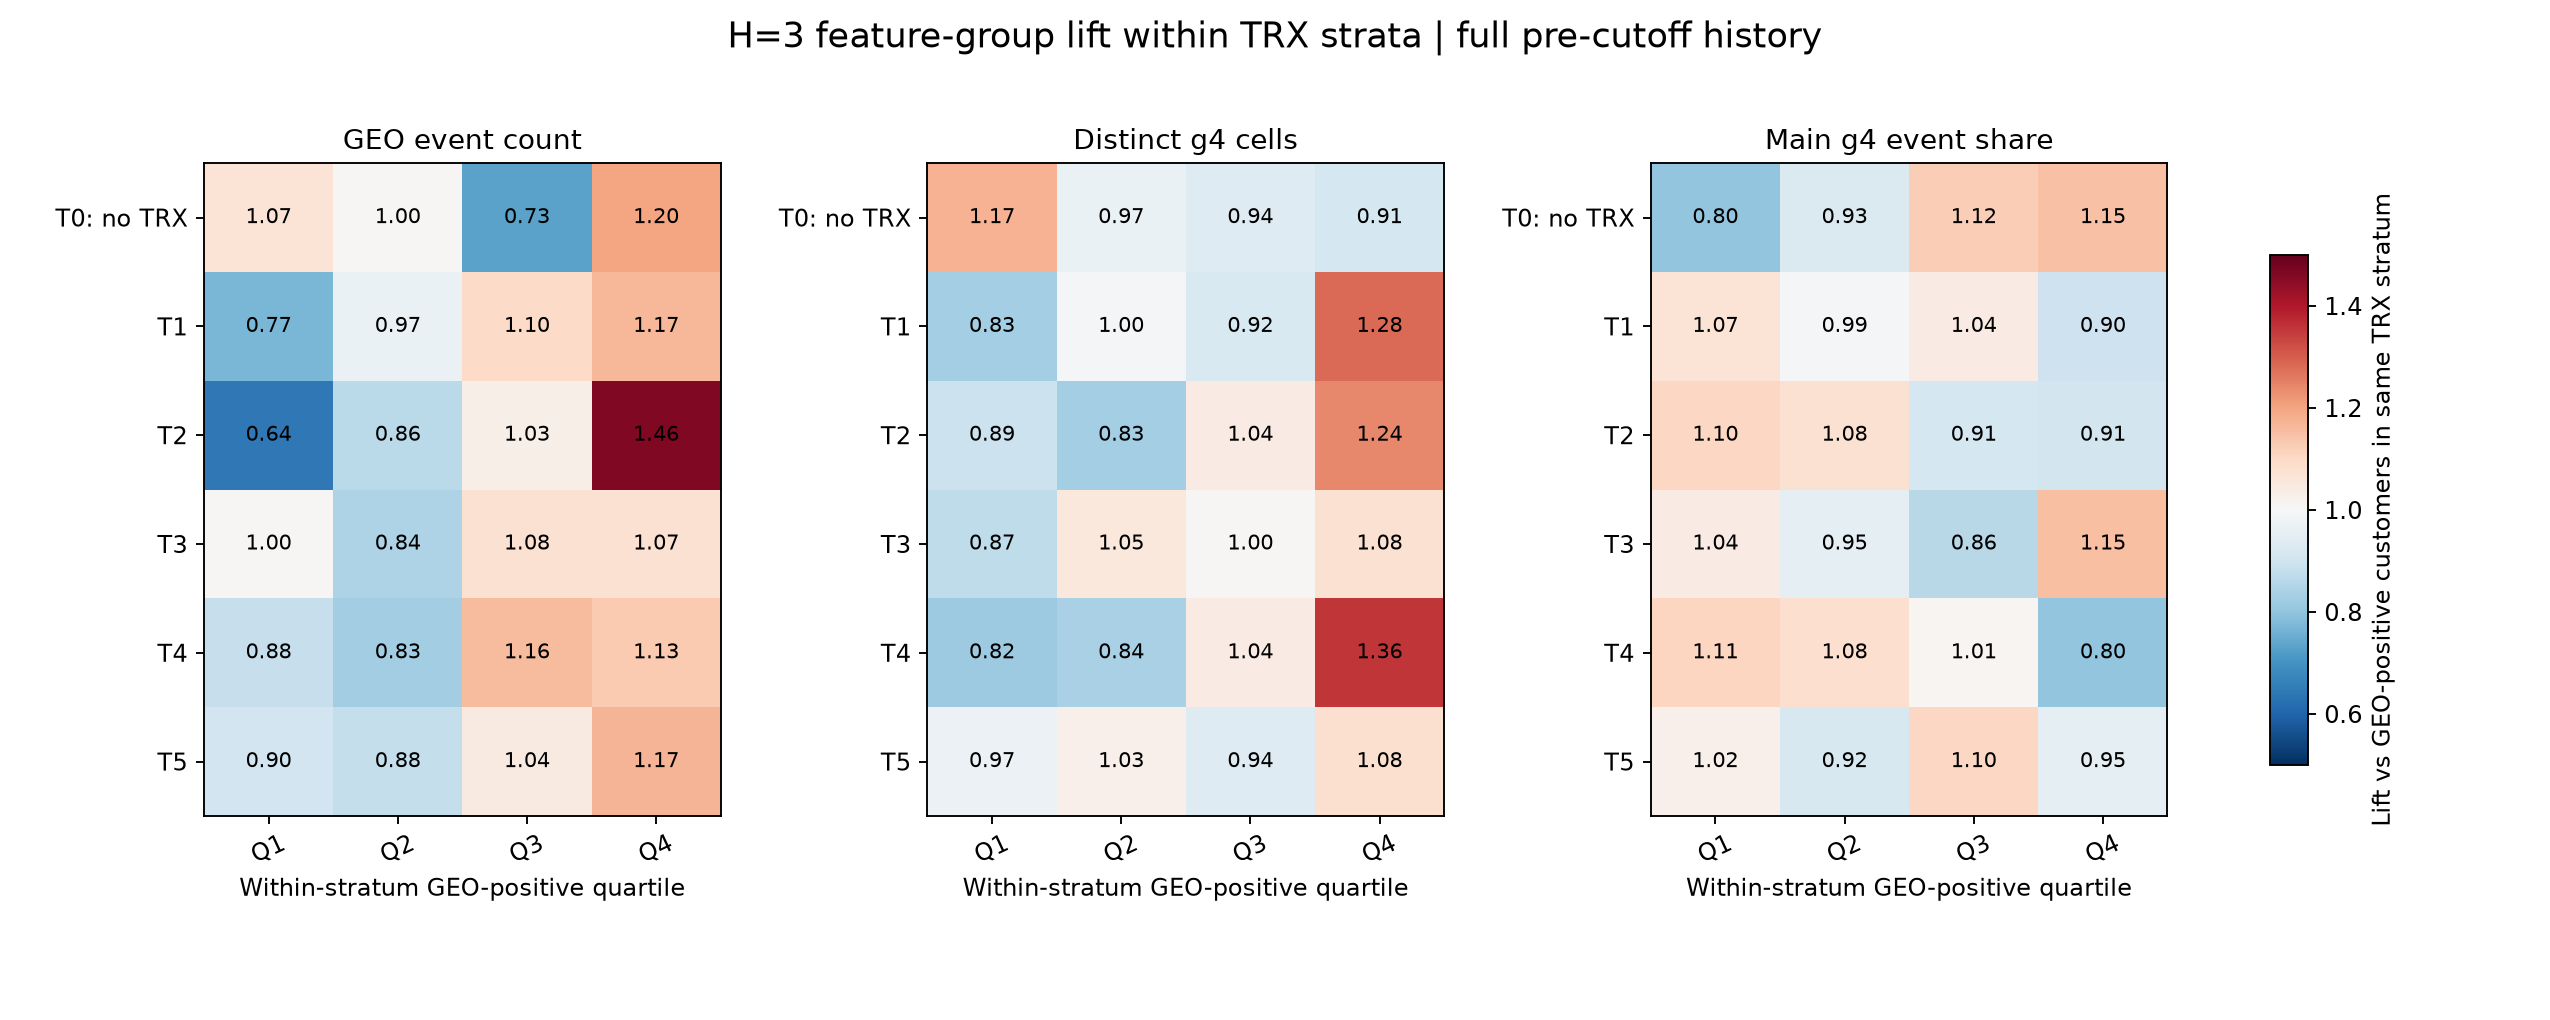

**outputs/geo_spatial_purchase_moscow_20261117/has_geo_stratified.png**

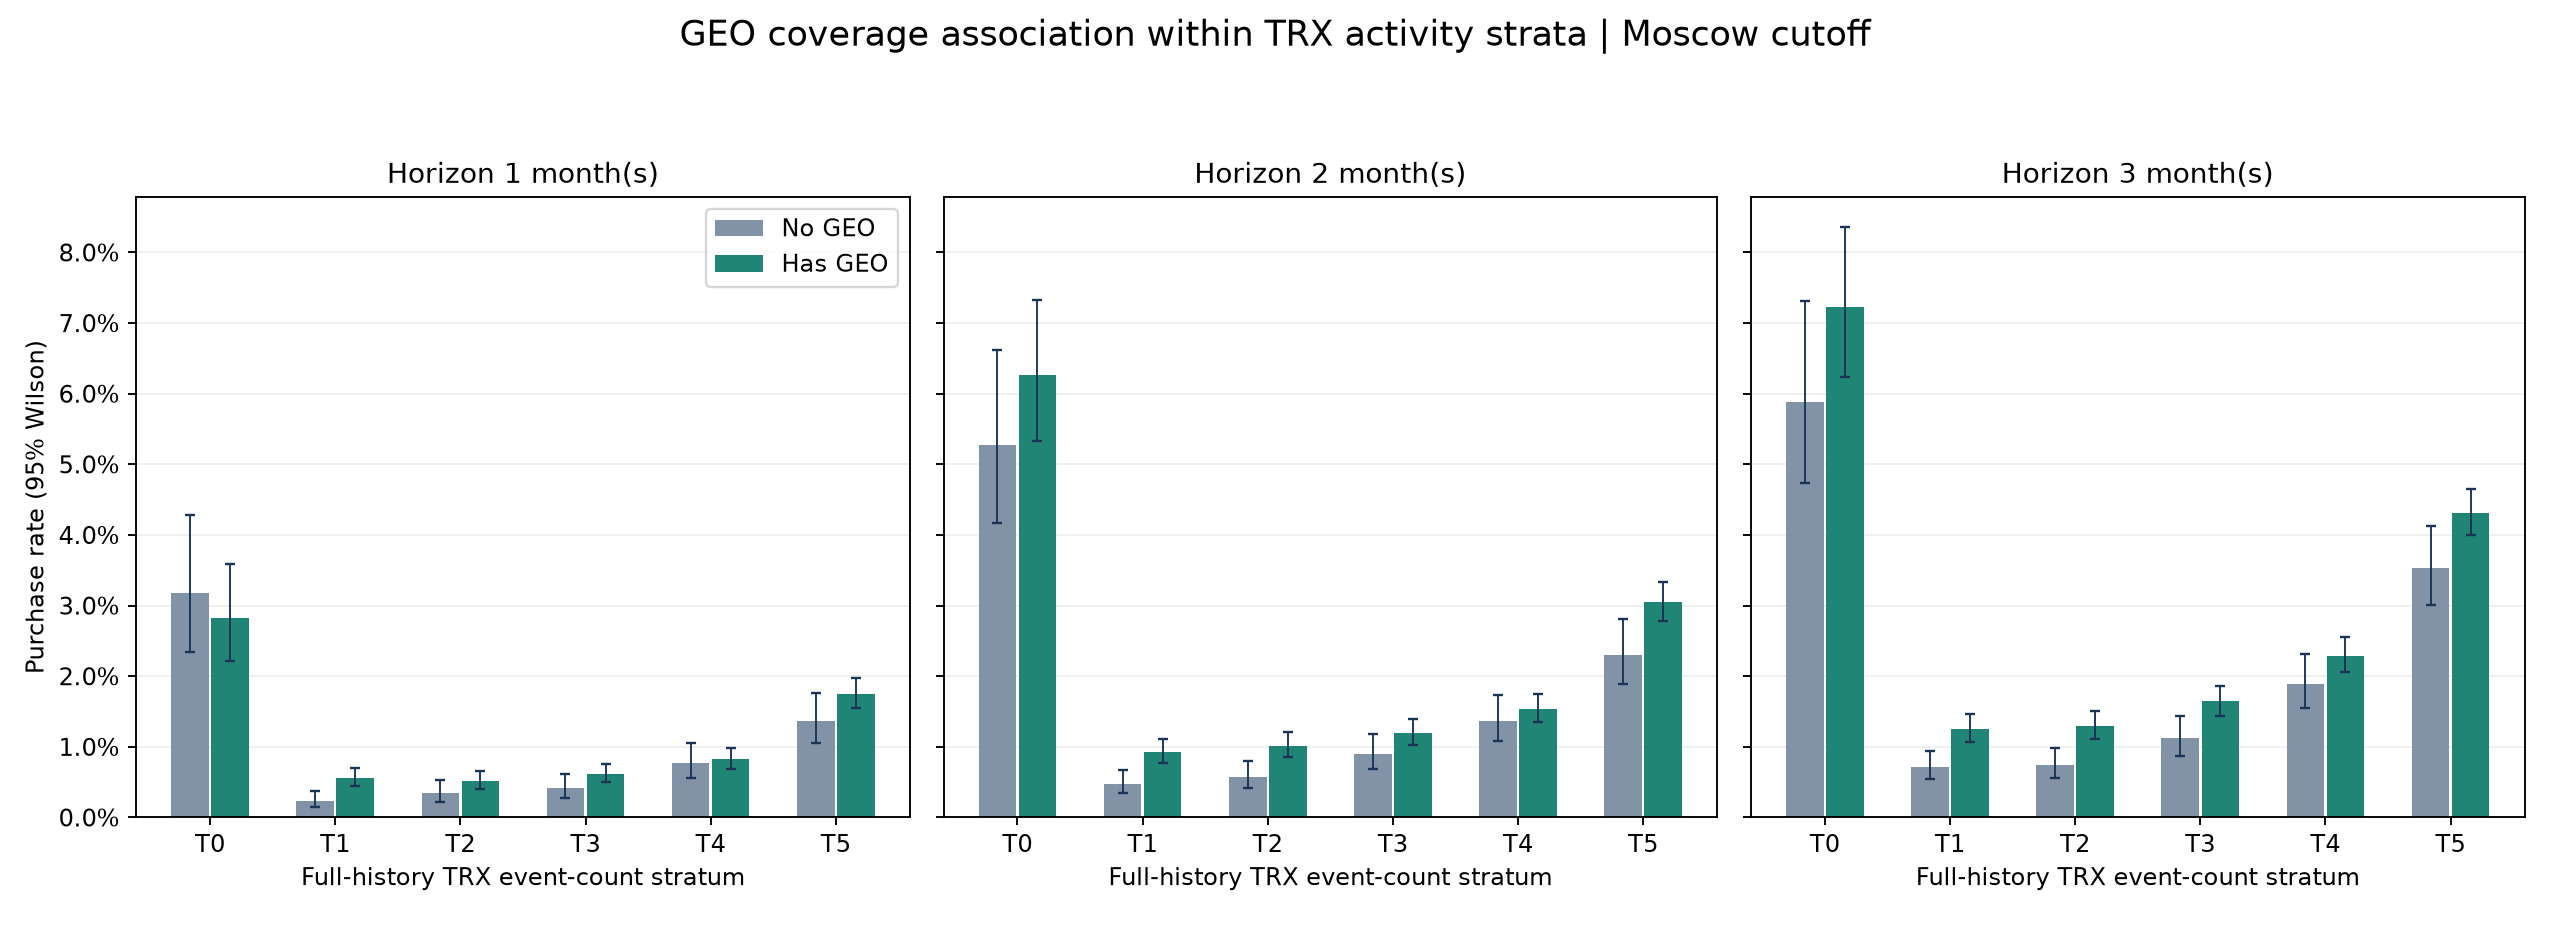

**outputs/geo_spatial_purchase_moscow_20261117/cell_support.csv** — 5 dòng đầu

,horizon,level,cells,cells_n_ge100,customers_n_ge100,median_n,cells_n_lt10,geo_customers
0,1,g4,4129,127,50447,2.0,3517,71311
1,1,g5,10889,124,19383,1.0,9663,71311
2,1,g6,33043,0,0,1.0,32237,71311
3,2,g4,4129,127,50447,2.0,3517,71311
4,2,g5,10889,124,19383,1.0,9663,71311


**outputs/geo_spatial_purchase_moscow_20261117/edges_geo_cells_g4_T0.csv** — 5 dòng đầu

,feature,trx_stratum,band,lower_edge,upper_edge
0,geo_cells_g4,T0: no TRX,Q1,1.0,3.0
1,geo_cells_g4,T0: no TRX,Q2,3.0,7.0
2,geo_cells_g4,T0: no TRX,Q3,7.0,14.0
3,geo_cells_g4,T0: no TRX,Q4,14.0,153.0


**outputs/geo_spatial_purchase_moscow_20261117/edges_geo_cells_g4_T1.csv** — 5 dòng đầu

,feature,trx_stratum,band,lower_edge,upper_edge
0,geo_cells_g4,T1,Q1,1.0,4.0
1,geo_cells_g4,T1,Q2,4.0,8.0
2,geo_cells_g4,T1,Q3,8.0,15.0
3,geo_cells_g4,T1,Q4,15.0,574.0


... (39 outputs left out)

,trx_stratum,has_geo,n,buyers,rate,wilson_low,wilson_high,horizon,stratum_baseline,lift_vs_stratum,rr_geo_vs_no_geo
0,T0: no TRX,False,1291,41,0.031758,0.023496,0.042799,1,0.029494,1.076759,0.888153
1,T0: no TRX,True,2269,64,0.028206,0.022151,0.035857,1,0.029494,0.956326,0.888153
2,T1,False,6868,16,0.002330,0.001435,0.003781,1,0.004461,0.522211,2.403640
3,T1,True,12858,72,0.005600,0.004449,0.007045,1,0.004461,1.255207,2.403640
4,T2,False,6089,21,0.003449,0.002257,0.005267,1,0.004638,0.743539,1.507941


**outputs/geo_spatial_purchase_moscow_20261117/hierarchical_cell_rates.csv** — 5 dòng đầu

,horizon,level,cell,parent_cell,n,buyers,rate,wilson_low,wilson_high,prior_mean,smoothed,data_weight,strength,baseline_all,meets_display_n100
0,1,g4,20.0,NaN,1,0,0.000000,0.000000e+00,0.793451,0.008651,0.008239,0.047619,20,0.008651,False
1,1,g4,24.0,NaN,12,0,0.000000,2.775558e-17,0.242494,0.008651,0.005407,0.375000,20,0.008651,False
2,1,g4,26.0,NaN,867,8,0.009227,4.682845e-03,0.018101,0.008651,0.009214,0.977452,20,0.008651,True
3,1,g4,35.0,NaN,2,0,0.000000,0.000000e+00,0.657620,0.008651,0.007864,0.090909,20,0.008651,False
4,1,g4,42.0,NaN,2,0,0.000000,0.000000e+00,0.657620,0.008651,0.007864,0.090909,20,0.008651,False


File kết quả khác: `outputs/geo_spatial_purchase_moscow_20261117/manifest.json`

In [7]:
show_generated_results(__eda_started_ns, 'src/scripts/analyze_geo_spatial_purchase_moscow.py')

## Analyze Geo Visitor Cell Rates

Nguồn: `src/scripts/analyze_geo_visitor_cell_rates.py`. Chạy các ô của phần này theo thứ tự.

In [8]:
__file__ = str(ROOT / 'src/scripts/analyze_geo_visitor_cell_rates.py')
sys.argv = [__file__]
__eda_started_ns = time.time_ns()
__name__ = '__main__'
__package__ = None


In [9]:
"""All-visitor cell rates; preserve client dependence in label permutations."""
from pathlib import Path
import numpy as np
import pandas as pd
import duckdb
from analyze_geo_spatial_purchase_moscow import OUT,CUTOFF,SEED,wilson


def main():
    d=pd.read_parquet(OUT/'customer_snapshot.parquet').reset_index(drop=True)
    ids=d[['client_id']].copy();ids['customer_index']=np.arange(len(d))
    cache=OUT/'visitor_memberships.parquet'
    if cache.exists():
        v=pd.read_parquet(cache)
    else:
        c=duckdb.connect();c.execute('SET threads=2');c.execute("SET memory_limit='3GB'")
        c.register('ids',ids)
        parts=[]
        for fold in range(5):
            parts.append(c.execute(f"SELECT DISTINCT i.customer_index,g.geohash_4 g4,g.geohash_5 g5,g.geohash_6 g6 FROM read_parquet('data/MBD-mini/detail/geo/fold={fold}/*.parquet') g JOIN ids i USING(client_id) WHERE g.event_time<TIMESTAMP '{CUTOFF}'").df())
            print('Visitor memberships fold',fold,flush=True)
        v=pd.concat(parts,ignore_index=True)
        v.to_parquet(cache,index=False)
    assert v.customer_index.nunique()==d.has_geo.sum()
    edges={};codes={};maps={};raw={}
    for level,parent in [('g4',None),('g5','g4'),('g6','g5')]:
        e=v[['customer_index']+([parent] if parent else [])+[level]].drop_duplicates()
        keys,index=pd.factorize(e[level],sort=True)
        edges[level]=e.customer_index.to_numpy(dtype=int);codes[level]=keys
        maps[level]=pd.DataFrame({'cell':index,'n':np.bincount(keys)})
        if parent:
            assert e.groupby(level)[parent].nunique().max()==1
            maps[level]['parent_cell']=maps[level].cell.map(e.drop_duplicates(level).set_index(level)[parent])
        else:maps[level]['parent_cell']=np.nan
        for h in [1,2,3]:
            r=maps[level].copy()
            r['buyers']=np.bincount(keys,weights=d[f'y_{h}'].to_numpy()[edges[level]]).astype(int)
            r['rate']=r.buyers/r.n
            r['wilson_low'],r['wilson_high']=wilson(r.buyers,r.n)
            r['horizon']=h;r['level']=level
            raw[(h,level)]=r
    smooth=[];support=[]
    for h in [1,2,3]:
        for level in ['g4','g5','g6']:
            r=raw[(h,level)]
            support.append(dict(horizon=h,level=level,cells=len(r),cells_n_ge100=int(r.n.ge(100).sum()),median_n=r.n.median(),cells_n_lt10=int(r.n.lt(10).sum())))
        for strength in [20,100,500]:
            previous=None
            for level in ['g4','g5','g6']:
                r=raw[(h,level)].copy()
                r['prior_mean']=d[f'y_{h}'].mean() if previous is None else r.parent_cell.map(previous.set_index('cell').smoothed)
                r['smoothed']=(r.buyers+strength*r.prior_mean)/(r.n+strength)
                r['data_weight']=r.n/(r.n+strength);r['strength']=strength
                smooth.append(r);previous=r
    pd.concat(smooth,ignore_index=True).to_parquet(OUT/'visitor_hierarchical_cell_rates.parquet',index=False)
    display=pd.concat([raw[(h,level)] for h in [1,2,3] for level in ['g4','g5']],ignore_index=True)
    display['meets_display_n100']=display.n.ge(100)
    display.to_csv(OUT/'visitor_g4_g5_wilson.csv',index=False)
    pd.DataFrame(support).to_csv(OUT/'visitor_cell_support.csv',index=False)
    # All edges of a customer use the same permuted label. Preserve TRX-stratum totals.
    mask=d.has_geo.to_numpy();blocks=[np.asarray(ix) for ix in d[mask].groupby('trx_stratum').groups.values()]
    tests=[];B=499
    for h in [1,2,3]:
        y=d[f'y_{h}'].to_numpy(dtype=float)
        p=np.zeros(len(d))
        for ix in blocks:p[ix]=y[ix].mean()
        specs={}
        for level in ['g4','g5']:
            code=codes[level];ci=edges[level]
            expected=np.bincount(code,weights=p[ci])
            variance=np.bincount(code,weights=p[ci]*(1-p[ci]));valid=variance>0
            def statistic(y,code=code,ci=ci,expected=expected,variance=variance,valid=valid):
                obs=np.bincount(code,weights=y[ci],minlength=len(expected))
                return np.sum((obs[valid]-expected[valid])**2/variance[valid])
            specs[level]=(statistic,float(statistic(y)),[])
        rng=np.random.default_rng(SEED+500+h)
        for _ in range(B):
            yp=y.copy()
            for ix in blocks:yp[ix]=rng.permutation(y[ix])
            for fun,observed,null in specs.values():null.append(float(fun(yp)))
        for level,(fun,observed,null) in specs.items():
            null=np.asarray(null)
            tests.append(dict(horizon=h,level=level,condition='within_trx_strata_all_visitors',customers=int(mask.sum()),cells=len(maps[level]),
                memberships=len(edges[level]),statistic=observed,null_mean=null.mean(),null_p95=np.quantile(null,.95),
                permutation_p=(1+int((null>=observed).sum()))/(B+1),permutations=B))
        print('Visitor permutations H=',h,flush=True)
    t=pd.DataFrame(tests)
    # Holm correction across all planned modal and visitor tests (18 comparisons).
    modal=pd.read_csv(OUT/'global_cell_permutation.csv')
    combined=pd.concat([modal.drop(columns='holm_p'),t],ignore_index=True)
    order=np.argsort(combined.permutation_p.to_numpy());adjusted=np.maximum.accumulate(combined.permutation_p.to_numpy()[order]*(len(combined)-np.arange(len(combined))))
    combined['holm_p']=0.0;combined.loc[order,'holm_p']=np.minimum(adjusted,1)
    combined.to_csv(OUT/'global_cell_permutation_all_definitions.csv',index=False)
    t=combined.tail(len(t));t.to_csv(OUT/'visitor_global_permutation.csv',index=False)
    for level in ['g4','g5','g6']:
        assert (raw[(3,level)].buyers<=raw[(3,level)].n).all()
        assert raw[(3,level)].n.sum()==len(edges[level])
    print(pd.DataFrame(support).query('horizon==3').to_string(index=False))
    print(t.to_string(index=False))


if __name__=='__main__':main()

Visitor permutations H= 1


Visitor permutations H= 2


Visitor permutations H= 3


 horizon level  cells  cells_n_ge100  median_n  cells_n_lt10
       3    g4  18067           1313       3.0         12185
       3    g5 116154           3115       2.0         94616
       3    g6 571008           9836       1.0        501175
 horizon level                      condition  customers  cells     statistic     null_mean      null_p95  permutation_p  permutations  memberships  holm_p
       1    g4 within_trx_strata_all_visitors      71311  18067  24963.563740  17975.217431  21929.695108          0.018           499     834050.0   0.288
       1    g5 within_trx_strata_all_visitors      71311 116154 145614.244659 115898.383207 131579.123932          0.006           499    2056809.0   0.108
       2    g4 within_trx_strata_all_visitors      71311  18067  22212.215606  17954.304780  21288.516457          0.032           499     834050.0   0.416
       2    g5 within_trx_strata_all_visitors      71311 116154 135516.673317 115914.556808 128990.457899          0.018           4

In [10]:
show_generated_results(__eda_started_ns, 'src/scripts/analyze_geo_visitor_cell_rates.py')

### Kết quả: `src/scripts/analyze_geo_visitor_cell_rates.py`

**outputs/geo_spatial_purchase_moscow_20261117/global_cell_permutation_all_definitions.csv** — 5 dòng đầu

,horizon,level,condition,customers,cells,statistic,null_mean,null_p95,permutation_p,permutations,memberships,holm_p
0,1,g4,unconditional,71311,4129,4359.188349,4138.683240,4948.020504,0.316,999,NaN,1.0
1,1,g5,unconditional,71311,10889,10866.708179,10908.273798,12209.327134,0.517,999,NaN,1.0
2,1,g4,within_trx_strata,71311,4129,3932.596816,4102.974753,4985.613462,0.631,999,NaN,1.0
3,1,g5,within_trx_strata,71311,10889,10367.943207,10851.666774,12258.631567,0.718,999,NaN,1.0
4,2,g4,unconditional,71311,4129,3892.408789,4124.458685,4698.137677,0.751,999,NaN,1.0


**outputs/geo_spatial_purchase_moscow_20261117/visitor_cell_support.csv** — 5 dòng đầu

,horizon,level,cells,cells_n_ge100,median_n,cells_n_lt10
0,1,g4,18067,1313,3.0,12185
1,1,g5,116154,3115,2.0,94616
2,1,g6,571008,9836,1.0,501175
3,2,g4,18067,1313,3.0,12185
4,2,g5,116154,3115,2.0,94616


**outputs/geo_spatial_purchase_moscow_20261117/visitor_g4_g5_wilson.csv** — 5 dòng đầu

,cell,n,parent_cell,buyers,rate,wilson_low,wilson_high,horizon,level,meets_display_n100
0,12,3,NaN,0,0.0,5.551115e-17,0.561497,1,g4,False
1,15,2,NaN,0,0.0,0.000000e+00,0.657620,1,g4,False
2,16,1,NaN,0,0.0,0.000000e+00,0.793451,1,g4,False
3,20,5,NaN,1,0.2,3.622411e-02,0.624465,1,g4,False
4,22,1,NaN,0,0.0,0.000000e+00,0.793451,1,g4,False


**outputs/geo_spatial_purchase_moscow_20261117/visitor_global_permutation.csv** — 5 dòng đầu

,horizon,level,condition,customers,cells,statistic,null_mean,null_p95,permutation_p,permutations,memberships,holm_p
0,1,g4,within_trx_strata_all_visitors,71311,18067,24963.563740,17975.217431,21929.695108,0.018,499,834050.0,0.288
1,1,g5,within_trx_strata_all_visitors,71311,116154,145614.244659,115898.383207,131579.123932,0.006,499,2056809.0,0.108
2,2,g4,within_trx_strata_all_visitors,71311,18067,22212.215606,17954.304780,21288.516457,0.032,499,834050.0,0.416
3,2,g5,within_trx_strata_all_visitors,71311,116154,135516.673317,115914.556808,128990.457899,0.018,499,2056809.0,0.288
4,3,g4,within_trx_strata_all_visitors,71311,18067,21265.947654,17877.463892,20588.849239,0.024,499,834050.0,0.336


File kết quả khác: `outputs/geo_spatial_purchase_moscow_20261117/visitor_hierarchical_cell_rates.parquet`